In [1]:
# download the 4 IMBIE shapefile parts
import urllib.request
base = "https://raw.githubusercontent.com/fliphilipp/FLUIDSuRRF-code/main/basins/shapefiles/Basins_IMBIE_Antarctica_v02."
[urllib.request.urlretrieve(base + e, "Basins_IMBIE_Antarctica_v02." + e) for e in ["shp", "shx", "dbf", "prj"]]

[('Basins_IMBIE_Antarctica_v02.shp',
  <http.client.HTTPMessage at 0x7efd300eda00>),
 ('Basins_IMBIE_Antarctica_v02.shx',
  <http.client.HTTPMessage at 0x7efd300ed520>),
 ('Basins_IMBIE_Antarctica_v02.dbf',
  <http.client.HTTPMessage at 0x7efd300ee9f0>),
 ('Basins_IMBIE_Antarctica_v02.prj',
  <http.client.HTTPMessage at 0x7efd300eecc0>)]

In [2]:
# where the files went
import os
os.getcwd()

'/home/users/aborow/ExtAnt-initial/notebooks'

In [4]:
# move the shapefile parts to scratch
import shutil, glob
dest = "/work/scratch-pw4/aborow/shapefiles/"
os.makedirs(dest, exist_ok=True)
[shutil.move(f, dest) for f in glob.glob("Basins_IMBIE_Antarctica_v02.*")]

['/work/scratch-pw4/aborow/shapefiles/Basins_IMBIE_Antarctica_v02.shp',
 '/work/scratch-pw4/aborow/shapefiles/Basins_IMBIE_Antarctica_v02.shx',
 '/work/scratch-pw4/aborow/shapefiles/Basins_IMBIE_Antarctica_v02.dbf',
 '/work/scratch-pw4/aborow/shapefiles/Basins_IMBIE_Antarctica_v02.prj']

In [9]:
import numpy as np
import xarray as xr

In [10]:
# sample data on a HadGEM3-like grid (1.25° x 1.875°), south of 40°S
lat = np.arange(-89.375, -40, 1.25)
lon = np.arange(0.9375, 360, 1.875)
tas = xr.DataArray(np.random.rand(10, lat.size, lon.size), coords={"time": range(10), "lat": lat, "lon": lon}, dims=("time", "lat", "lon"), name="tas")
tas

<xarray.DataArray 'tas' (time: 10, lat: 40, lon: 192)> Size: 614kB
array([[[0.03749281, 0.84576341, 0.52934307, ..., 0.58743861,
         0.87852567, 0.3331901 ],
        [0.68397769, 0.8742186 , 0.60009953, ..., 0.4820374 ,
         0.83668518, 0.40640814],
        [0.9246303 , 0.27887813, 0.30027692, ..., 0.75835901,
         0.88645381, 0.12234276],
        ...,
        [0.10486684, 0.11387217, 0.31992453, ..., 0.28913384,
         0.21700042, 0.74277517],
        [0.1051609 , 0.23039762, 0.30553025, ..., 0.41526018,
         0.56321981, 0.80602852],
        [0.5933376 , 0.66372943, 0.77082605, ..., 0.13718441,
         0.95674163, 0.7536548 ]],

       [[0.85925475, 0.98662439, 0.34608573, ..., 0.19723995,
         0.19167419, 0.68282667],
        [0.30226292, 0.84893284, 0.40223121, ..., 0.92915094,
         0.88575873, 0.93601016],
        [0.72962096, 0.443345  , 0.37514369, ..., 0.81894844,
         0.60398542, 0.51312596],
...
        [0.72453458, 0.59857718, 0.29528812, ..., 0.58651666,
         0.54591111, 0.94234052],
        [0.67524909, 0.34147502, 0.57698689, ..., 0.63459582,
         0.47757746, 0.73745404],
        [0.90940311, 0.02725216, 0.25253226, ..., 0.25847138,
         0.25891587, 0.39797678]],

       [[0.95369749, 0.00447248, 0.20910015, ..., 0.39588805,
         0.93610175, 0.54903785],
        [0.58858864, 0.28535008, 0.50988208, ..., 0.06684978,
         0.57187831, 0.92324892],
        [0.4693604 , 0.34853443, 0.58898175, ..., 0.53793185,
         0.53312095, 0.40447422],
        ...,
        [0.05992005, 0.8215394 , 0.0370036 , ..., 0.2913607 ,
         0.00747489, 0.67144039],
        [0.13289766, 0.26320163, 0.61842178, ..., 0.44583027,
         0.52969171, 0.2128267 ],
        [0.45377021, 0.66169175, 0.67164788, ..., 0.93698834,
         0.59081367, 0.8700395 ]]], shape=(10, 40, 192))
Coordinates:
  * time     (time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * lat      (lat) float64 320B -89.38 -88.12 -86.88 ... -43.12 -41.88 -40.62
  * lon      (lon) float64 2kB 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1

In [12]:
# IMBIE label per grid cell
import geopandas as gpd
gdf = gpd.read_file("/work/scratch-pw4/aborow/shapefiles/Basins_IMBIE_Antarctica_v02.shp")

In [16]:
gdf.head()

,NAME,Regions,Subregions,TYPE,geometry
0,None,Islands,None,IS,"MULTIPOLYGON (((-217776.532 2130382.522, -2168..."
1,A-Ap,East,A-Ap,GR,"POLYGON ((1233919.752 1935020.761, 1237354.55 ..."
2,Ap-B,East,Ap-B,GR,"POLYGON ((1267480.529 1935993.733, 1261072.64 ..."
3,B-C,East,B-C,GR,"POLYGON ((1672255.018 -94566.965, 1625433.485 ..."
4,C-Cp,East,C-Cp,GR,"POLYGON ((2594276.532 -575938.016, 2594114.248..."


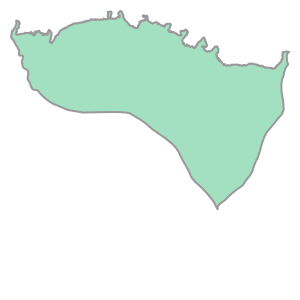

In [19]:
gdf.iloc[1, -1]

<Axes: >

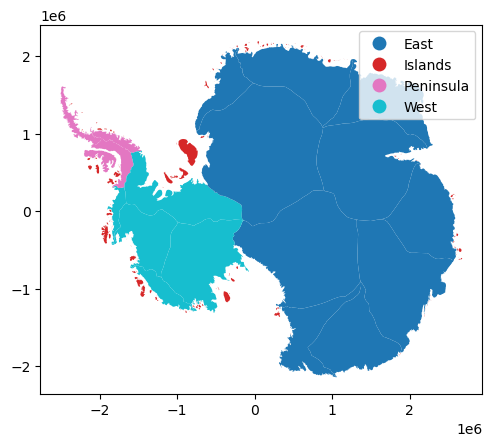

In [15]:
gdf.plot(column='Regions', legend=True)

In [23]:
# gpd.GeoDataFrame?

In [26]:
# gpd.points_from_xy?

In [27]:
gdf.crs

<Projected CRS: EPSG:3031>
Name: WGS 84 / Antarctic Polar Stereographic
Axis Info [cartesian]:
- E[north]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Antarctica.
- bounds: (-180.0, -90.0, 180.0, -60.0)
Coordinate Operation:
- name: Antarctic Polar Stereographic
- method: Polar Stereographic (variant B)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [20]:
lon2, lat2 = np.meshgrid((tas.lon + 180) % 360 - 180, tas.lat)
pts = gpd.GeoDataFrame(geometry=gpd.points_from_xy(lon2.ravel(), lat2.ravel()), crs=4326).to_crs(gdf.crs)
pts

,geometry
0,POINT (1111.099 67899.332)
1,POINT (3332.108 67826.624)
2,POINT (5549.549 67681.285)
3,POINT (7761.048 67463.472)
4,POINT (9964.235 67173.416)
...,...
7675,POINT (-837824.503 5648154.011)
7676,POINT (-652573.502 5672542.768)
7677,POINT (-466623.71 5690857.224)
7678,POINT (-280174.245 5703077.767)


In [31]:
gdf.head()

,NAME,Regions,Subregions,TYPE,geometry
0,None,Islands,None,IS,"MULTIPOLYGON (((-217776.532 2130382.522, -2168..."
1,A-Ap,East,A-Ap,GR,"POLYGON ((1233919.752 1935020.761, 1237354.55 ..."
2,Ap-B,East,Ap-B,GR,"POLYGON ((1267480.529 1935993.733, 1261072.64 ..."
3,B-C,East,B-C,GR,"POLYGON ((1672255.018 -94566.965, 1625433.485 ..."
4,C-Cp,East,C-Cp,GR,"POLYGON ((2594276.532 -575938.016, 2594114.248..."


In [ ]:
gpd.sjoin(pts, gdf[["Regions", "geometry"]], how="left")

In [29]:
lab = gpd.sjoin(pts, gdf[["Regions", "geometry"]], how="left").groupby(level=0).Regions.first()
lab

0       East
1       East
2       East
3       East
4       East
        ... 
7675    None
7676    None
7677    None
7678    None
7679    None
Name: Regions, Length: 7680, dtype: object

In [11]:
basin = xr.DataArray(lab.values.reshape(lon2.shape), coords={"lat": tas.lat, "lon": tas.lon})
basin

<xarray.DataArray (lat: 40, lon: 192)> Size: 61kB
array([['East', 'East', 'East', ..., 'East', 'East', 'East'],
       ['East', 'East', 'East', ..., 'East', 'East', 'East'],
       ['East', 'East', 'East', ..., 'East', 'East', 'East'],
       ...,
       [None, None, None, ..., None, None, None],
       [None, None, None, ..., None, None, None],
       [None, None, None, ..., None, None, None]],
      shape=(40, 192), dtype=object)
Coordinates:
  * lat      (lat) float64 320B -89.38 -88.12 -86.88 ... -43.12 -41.88 -40.62
  * lon      (lon) float64 2kB 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1

In [36]:
# number for each IMBIE region (0 = outside the polygons)
codes = {"East": 1, "West": 2, "Peninsula": 3}
basin_id = sum(i * (basin == name) for name, i in codes.items())

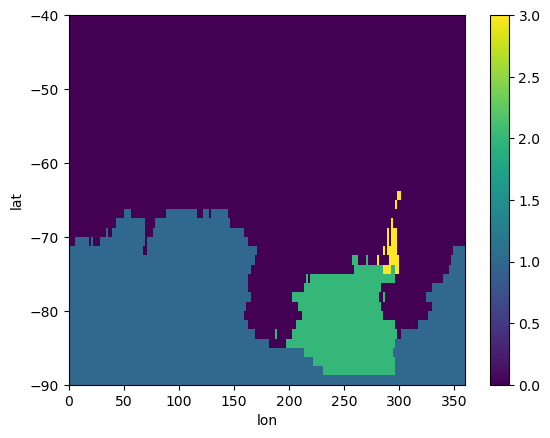

In [37]:
basin_id.plot()

In [38]:
# sea-ice sector by longitude, Parkinson & Cavalieri 2012
l = (tas.lon + 180) % 360 - 180
sector = xr.where((l >= -60) & (l < 20), "Weddell",
         xr.where((l >= 20) & (l < 90), "Indian",
         xr.where((l >= 90) & (l < 160), "W Pacific",
         xr.where((l >= -130) & (l < -60), "Amundsen-Bell.", "Ross"))))

In [39]:
# sea-ice sector by longitude, Parkinson & Cavalieri 2012
l = (tas.lon + 180) % 360 - 180
sector = xr.where((l >= -60) & (l < 20), "Weddell",
         xr.where((l >= 20) & (l < 90), "Indian",
         xr.where((l >= 90) & (l < 160), "W Pacific",
         xr.where((l >= -130) & (l < -60), "Amundsen-Bell.", "Ross"))))

In [42]:
# IMBIE name on the continent, sector everywhere else
region = xr.where(basin.isin(["East", "West", "Peninsula"]), basin, sector)

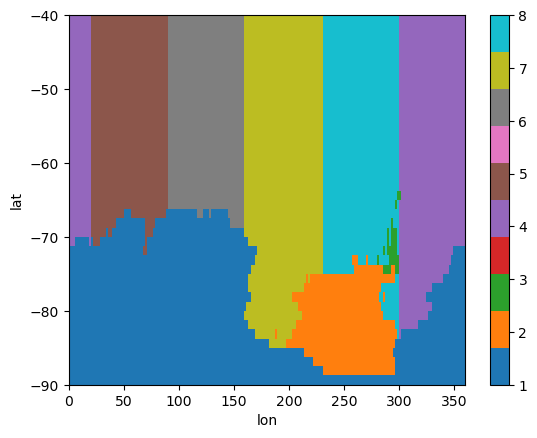

In [43]:
# number for each region
codes = {"East": 1, "West": 2, "Peninsula": 3, "Weddell": 4, "Indian": 5, "W Pacific": 6, "Ross": 7, "Amundsen-Bell.": 8}
region_id = sum(i * (region == name) for name, i in codes.items())
region_id.plot(cmap="tab10")

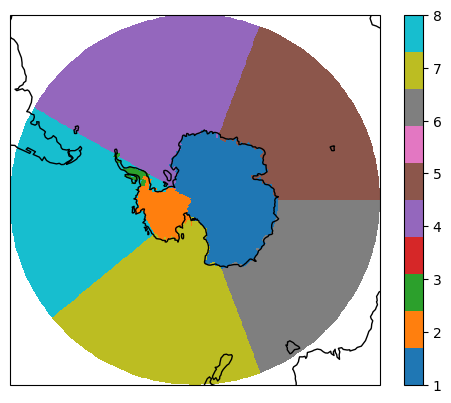

In [44]:
# regions on a south polar map
import matplotlib.pyplot as plt, cartopy.crs as ccrs
ax = plt.axes(projection=ccrs.SouthPolarStereo())
region_id.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="tab10")
ax.coastlines()